# DeepFER – Phase 2: Duplicate Remediation & Image Preprocessing

**Environment:** Google Colab  
**Input:** Original facial emotion ZIP  
**Phase 1 findings:** 35,887 images; 7 classes; 48×48 pixels; 0 corrupt images; 1,516 exact-duplicate hash groups; 510 duplicate groups spanning train/validation; 57 groups with conflicting labels; no independent test split.

## What this notebook does
1. Re-upload and extract the original dataset.
2. Build a canonical manifest without counting mirrored archive folders twice.
3. Compute SHA-256 hashes and verify images.
4. Remove ambiguous hash groups with conflicting emotion labels.
5. Deduplicate identical content with the same label.
6. Create a fresh stratified 80/10/10 train/validation/test split after deduplication.
7. Save standardized 48×48 grayscale images into clean class folders.
8. Export manifests, quality reports and a split ZIP.

**Important:** We split unique image hashes, not the original train/validation folders. This prevents exact duplicate images crossing the new splits. Keep the original dataset unchanged.

## 1. Install dependencies

In [ ]:
!pip -q install pillow pandas numpy matplotlib seaborn scikit-learn

## 2. Upload the original dataset ZIP

In [ ]:
from google.colab import files
uploaded = files.upload()
zip_candidates = [n for n in uploaded if n.lower().endswith(".zip")]
if not zip_candidates:
    raise FileNotFoundError("Upload the original DeepFER dataset ZIP.")
ZIP_PATH = zip_candidates[0]
print("Using:", ZIP_PATH)

Saving Face Emotion Recognition Dataset (1).zip to Face Emotion Recognition Dataset (1).zip
Using: Face Emotion Recognition Dataset (1).zip


## 3. Extract archive

In [ ]:
from pathlib import Path
import zipfile, shutil, os

EXTRACT_DIR = Path("/content/deepfer_phase2_extracted")
if EXTRACT_DIR.exists():
    shutil.rmtree(EXTRACT_DIR)
EXTRACT_DIR.mkdir(parents=True)

with zipfile.ZipFile(ZIP_PATH) as zf:
    zf.extractall(EXTRACT_DIR)

print("Extracted to:", EXTRACT_DIR)

Extracted to: /content/deepfer_phase2_extracted


## 4. Build canonical manifest

The archive contains a mirrored nested `images/images` tree. This code selects one canonical copy per split, class and relative image filename.

In [ ]:
import pandas as pd
from PIL import Image, ImageOps
import hashlib

CLASSES = ["angry", "disgust", "fear", "happy", "neutral", "sad", "surprise"]
VALID_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
SPLITS = {"train", "validation", "test"}

files_all = [p for p in EXTRACT_DIR.rglob("*") if p.is_file() and p.suffix.lower() in VALID_EXT]
rows = []
for p in files_all:
    parts = p.parts
    split_idx = next((i for i, part in enumerate(parts) if part.lower() in SPLITS), None)
    if split_idx is None or split_idx + 1 >= len(parts):
        continue
    split, label = parts[split_idx].lower(), parts[split_idx+1].lower()
    if label in CLASSES:
        rows.append({"path": str(p), "source_split": split, "emotion": label,
                     "relative_image": "/".join(parts[split_idx+2:])})

manifest = pd.DataFrame(rows)
if manifest.empty:
    raise ValueError("No split/class image folders found. Inspect the extracted folder structure.")

manifest = manifest.drop_duplicates(
    subset=["source_split", "emotion", "relative_image"], keep="first"
).reset_index(drop=True)
print("Canonical file count:", len(manifest))
display(manifest.groupby(["source_split","emotion"]).size().unstack(fill_value=0))

Canonical file count: 35887


emotion,angry,disgust,fear,happy,neutral,sad,surprise
source_split,,,,,,,
train,3993,436,4103,7164,4982,4938,3205
validation,960,111,1018,1825,1216,1139,797


## 5. Validate, hash and inspect dimensions

SHA-256 identifies byte-identical files. The image is decoded and converted to grayscale 48×48 using Pillow. No resize is needed for this dataset if the Phase 1 dimensions are confirmed.

In [ ]:
valid_rows, corrupt_rows = [], []
for r in manifest.itertuples(index=False):
    try:
        raw = Path(r.path).read_bytes()
        digest = hashlib.sha256(raw).hexdigest()
        with Image.open(r.path) as im:
            im.verify()
        with Image.open(r.path) as im:
            w, h = im.size
            mode = im.mode
        valid_rows.append({
            "path": r.path, "source_split": r.source_split, "emotion": r.emotion,
            "width": w, "height": h, "mode": mode, "sha256": digest
        })
    except Exception as e:
        corrupt_rows.append({"path": r.path, "error": str(e)})

df = pd.DataFrame(valid_rows)
corrupt_df = pd.DataFrame(corrupt_rows)
print("Valid:", len(df), "| Corrupt:", len(corrupt_df))
print("Dimensions:")
display(df.groupby(["width","height"]).size().reset_index(name="images"))

Valid: 35887 | Corrupt: 0
Dimensions:


,width,height,images
0,48,48,35887


## 6. Resolve exact duplicates and conflicting labels

Policy:
- If one SHA-256 hash is associated with more than one emotion label, exclude that hash group from supervised training. Its label is ambiguous.
- If a hash appears multiple times with the same label, keep one copy only.
- This is a conservative, auditable policy. The removed records are saved for review; do not silently relabel them.

In [ ]:
label_counts = df.groupby("sha256")["emotion"].nunique()
conflict_hashes = set(label_counts[label_counts > 1].index)

conflict_df = df[df.sha256.isin(conflict_hashes)].copy()
unambiguous = df[~df.sha256.isin(conflict_hashes)].copy()

# One unique byte-content image per hash, same label.
dedup_df = unambiguous.sort_values(["sha256","path"]).drop_duplicates("sha256", keep="first").copy()

print("Raw valid rows:", len(df))
print("Conflicting hash groups:", len(conflict_hashes))
print("Rows excluded due to conflicting labels:", len(conflict_df))
print("Rows after exact deduplication:", len(dedup_df))
print("Duplicate rows removed:", len(unambiguous) - len(dedup_df))

display(conflict_df.groupby(["sha256","emotion"]).size().head(20))

Raw valid rows: 35887
Conflicting hash groups: 57
Rows excluded due to conflicting labels: 160
Rows after exact deduplication: 33977
Duplicate rows removed: 1750


sha256                                                            emotion 
00567c7d6e6a818b519975b54a0bee17eab150fda91b951220d6f92f836ee47d  disgust     3
                                                                  fear        1
099a979fe46008f0ca1a18010a24cacfb8409bbb74458354dc79c46b7217e196  fear        1
                                                                  surprise    1
161a9457d5003123ed0de94a488f3a7f8cc7e1fe3c582c3fbfc11dcc6a38e4df  fear        1
                                                                  neutral     1
200ac8bc39d686ea129cd47222c98de46b686793ebec188a73cd52a7348bee12  fear        1
                                                                  sad         2
24e4ef151fe2569290f421101c336006c5c30dd671f5aa570c61d7f4374ee3e4  angry       1
                                                                  sad         2
26bea2f8e1061751133a59b2ed374700e805e444c09a3b422741a72abfe5eab9  happy       1
                                                                  surprise    1
31b92518b24475f181142b5da8c08bc83f679516f8b2c1dc62ccab69b721273b  angry       1
                                                                  fear        1
3470c8a8b77d86a3fda906c7dca2d461fa5a4d6a18da82303c1f55b89fccc135  fear        1
                                                                  surprise    1
35a5e499e179360a5da52d92e3d48a55e76e26ba3dad53075912655cb50ccf6c  angry       1
                                                                  fear        1
455f5a2c71ffe9a25cbb853a02aad0b7211a1f5c65bec57e9d13c557c731c3ba  happy       1
                                                                  surprise    1
dtype: int64

## 7. Create leakage-safe stratified 80/10/10 split

After exact-content deduplication, each SHA-256 occurs once. We can stratify unique images by emotion and create a new split. Original train/validation labels are retained only for audit, not used to preserve the old split.

In [ ]:
from sklearn.model_selection import train_test_split

if set(dedup_df.emotion.unique()) != set(CLASSES):
    raise ValueError("At least one class is absent after conflict removal. Review the conflict report before proceeding.")

train_df, temp_df = train_test_split(
    dedup_df, test_size=0.20, random_state=42, stratify=dedup_df["emotion"]
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=42, stratify=temp_df["emotion"]
)

train_df = train_df.assign(new_split="train")
val_df = val_df.assign(new_split="validation")
test_df = test_df.assign(new_split="test")
split_df = pd.concat([train_df, val_df, test_df], ignore_index=True)

assert split_df.sha256.is_unique, "Exact duplicate leakage detected!"
print("Train:", len(train_df), "Validation:", len(val_df), "Test:", len(test_df))
display(split_df.groupby(["new_split","emotion"]).size().unstack(fill_value=0))

Train: 27181 Validation: 3398 Test: 3398


emotion,angry,disgust,fear,happy,neutral,sad,surprise
new_split,,,,,,,
test,472,46,480,879,605,591,325
train,3774,366,3842,7035,4837,4729,2598
validation,471,46,480,880,604,592,325


## 8. Standardize images and write clean folder structure

We preserve 48×48 grayscale images for the baseline CNN. For transfer learning, a later input pipeline will convert them to three channels and resize to the chosen pretrained model's input size. This avoids storing redundant 224×224 copies.

In [ ]:
from PIL import Image
from pathlib import Path
import shutil

OUTPUT_DIR = Path("/content/DeepFER/processed")
if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)

for row in split_df.itertuples(index=False):
    dest_dir = OUTPUT_DIR / row.new_split / row.emotion
    dest_dir.mkdir(parents=True, exist_ok=True)
    dest = dest_dir / f"{row.sha256}.png"

    with Image.open(row.path) as im:
        im = ImageOps.exif_transpose(im).convert("L")
        if im.size != (48, 48):
            im = im.resize((48, 48), Image.Resampling.LANCZOS)
        im.save(dest, format="PNG", optimize=True)

print("Processed dataset created:", OUTPUT_DIR)

Processed dataset created: /content/DeepFER/processed


## 9. Validate processed output and visualize samples

Processed image count: 33977


emotion,angry,disgust,fear,happy,neutral,sad,surprise
split,,,,,,,
test,472,46,480,879,605,591,325
train,3774,366,3842,7035,4837,4729,2598
validation,471,46,480,880,604,592,325


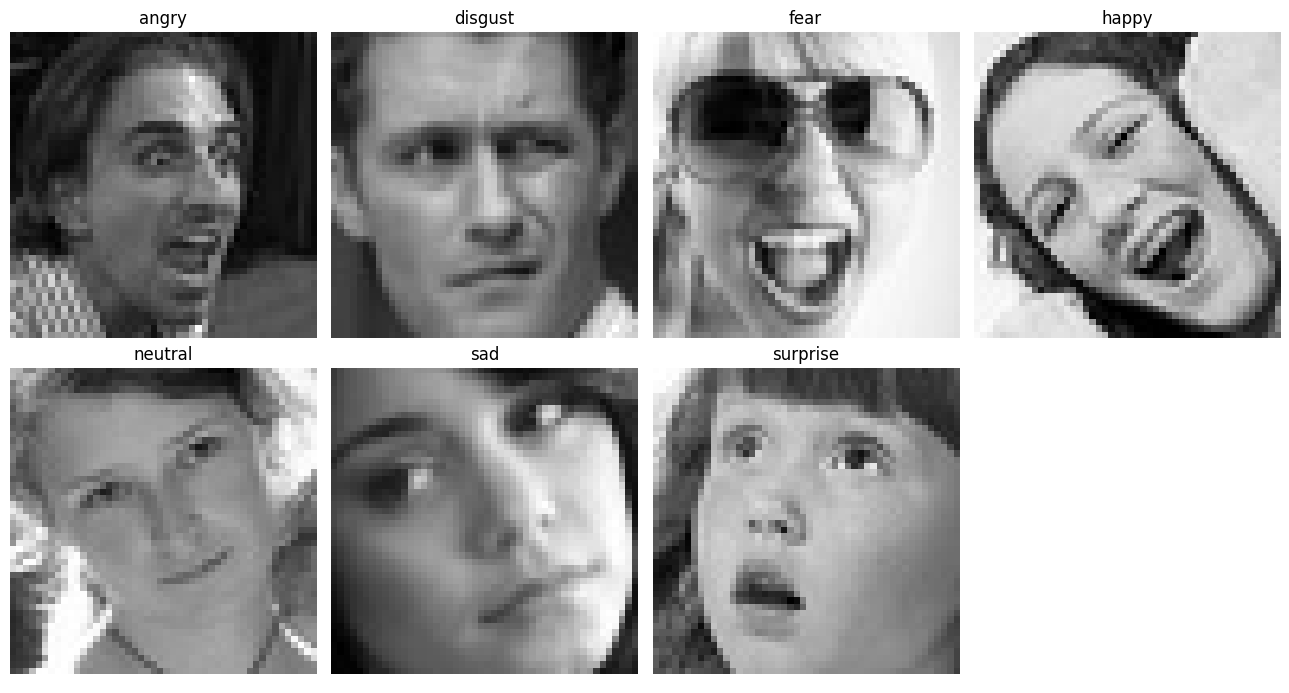

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

processed_rows = []
for split in ["train","validation","test"]:
    for emotion in CLASSES:
        for p in (OUTPUT_DIR/split/emotion).glob("*.png"):
            with Image.open(p) as im:
                assert im.size == (48,48)
                assert im.mode == "L"
            processed_rows.append({"split":split,"emotion":emotion,"path":str(p)})

processed_df = pd.DataFrame(processed_rows)
print("Processed image count:", len(processed_df))
display(processed_df.groupby(["split","emotion"]).size().unstack(fill_value=0))

fig, axes = plt.subplots(2,4,figsize=(13,7))
for ax, emotion in zip(axes.flat, CLASSES+[""]):
    if not emotion:
        ax.axis("off"); continue
    sample = processed_df[processed_df.emotion==emotion].sample(1,random_state=42).iloc[0]
    ax.imshow(Image.open(sample.path), cmap="gray")
    ax.set_title(emotion); ax.axis("off")
plt.tight_layout(); plt.show()

In [ ]:
import json

## 10. Export Phase 2 audit reports and clean dataset ZIP

In [ ]:
REPORT_DIR = Path("/content/DeepFER/reports")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

df.to_csv(REPORT_DIR/"phase2_validated_source_manifest.csv", index=False)
conflict_df.to_csv(REPORT_DIR/"conflicting_label_images.csv", index=False)
split_df.to_csv(REPORT_DIR/"leakage_safe_split_manifest.csv", index=False)
corrupt_df.to_csv(REPORT_DIR/"corrupt_images.csv", index=False)
processed_df.to_csv(REPORT_DIR/"processed_image_manifest.csv", index=False)

split_counts = split_df.groupby(["new_split","emotion"]).size().unstack(fill_value=0)
split_counts.to_csv(REPORT_DIR/"final_split_class_counts.csv")

summary = {
    "source_valid_images": int(len(df)),
    "corrupt_images": int(len(corrupt_df)),
    "conflicting_hash_groups_excluded": int(len(conflict_hashes)),
    "conflicting_rows_excluded": int(len(conflict_df)),
    "unique_images_after_dedup": int(len(dedup_df)),
    "duplicate_rows_removed": int(len(unambiguous)-len(dedup_df)),
    "final_split_counts": {s: int((split_df.new_split==s).sum()) for s in ["train","validation","test"]},
    "exact_hashes_unique_after_split": bool(split_df.sha256.is_unique),
    "image_size": "48x48 grayscale",
    "seed": 42
}
with open(REPORT_DIR/"phase2_summary.json","w") as f:
    json.dump(summary,f,indent=2)

shutil.make_archive("/content/DeepFER_processed_dataset","zip",OUTPUT_DIR)
shutil.make_archive("/content/DeepFER_Phase2_Reports","zip",REPORT_DIR)

from google.colab import files
files.download("/content/DeepFER_Phase2_Reports.zip")
files.download("/content/DeepFER_processed_dataset.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Phase 2 completion checklist

- [ ] All seven classes remain represented after ambiguous-label exclusion.
- [ ] Conflicting-label duplicate groups have been excluded and logged.
- [ ] Identical same-label images have been deduplicated.
- [ ] New 80/10/10 split is stratified.
- [ ] No SHA-256 hash appears in more than one split.
- [ ] All processed images are 48×48 grayscale PNG.
- [ ] Phase 2 summary and manifests have been downloaded.

Do not use the test set for model selection or hyperparameter tuning. It is reserved for final evaluation after model selection.